# 01 · First shot chart

Step 1 of HoopScholar: pull one player's shots for one season from stats.nba.com with `nba_api`,
and plot them over a half court with matplotlib.

**Run this on your own computer.** stats.nba.com ignores most cloud and notebook-hosting IPs (Colab, AWS, etc.).
If the request fails, the notebook falls back to the demo database (`python scripts/make_demo_data.py`) so the plots still work.

In [1]:
# Run once in your environment:
# %pip install nba_api pandas matplotlib

In [2]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Arc, Circle, Rectangle
from nba_api.stats.endpoints import shotchartdetail
from nba_api.stats.static import players

SEASON = "2025-26"
PLAYER_NAME = "Nikola Jokic"   # try anyone; search ignores accents and case

## 1. Look up the player
Player IDs ship with the package, so this works offline.

In [3]:
matches = players.find_players_by_full_name(PLAYER_NAME)
matches

[{'id': 203999,
  'full_name': 'Nikola Jokić',
  'first_name': 'Nikola',
  'last_name': 'Jokić',
  'is_active': True}]

In [4]:
player = matches[0]
PLAYER_ID = player["id"]
print(player["full_name"], PLAYER_ID)

Nikola Jokić 203999


## 2. Pull the shot chart
`ShotChartDetail` returns every field-goal attempt with its court location.
`team_id=0` means "any team" and `context_measure_simple="FGA"` includes misses (the default is makes only).

In [5]:
def fetch_shots(player_id, season):
    resp = shotchartdetail.ShotChartDetail(
        team_id=0,
        player_id=player_id,
        season_nullable=season,
        season_type_all_star="Regular Season",
        context_measure_simple="FGA",
        timeout=20,
    )
    shots, league_avgs = resp.get_data_frames()
    return shots, league_avgs


def demo_shots():
    """Fallback: a player from the demo DB, renamed to nba_api's column names."""
    db = Path("..") / "data" / "demo.db"
    con = sqlite3.connect(db)
    pid = con.execute("SELECT player_id FROM player_season_stats ORDER BY pts DESC LIMIT 1").fetchone()[0]
    df = pd.read_sql_query("SELECT s.*, p.full_name FROM shots s JOIN players p USING(player_id) WHERE player_id=?",
                           con, params=(pid,))
    return df.rename(columns={
        "loc_x": "LOC_X", "loc_y": "LOC_Y", "made": "SHOT_MADE_FLAG", "zone_basic": "SHOT_ZONE_BASIC",
        "distance": "SHOT_DISTANCE", "action_type": "ACTION_TYPE", "shot_type": "SHOT_TYPE",
        "full_name": "PLAYER_NAME", "game_date": "GAME_DATE"}), None


try:
    shots, league_avgs = fetch_shots(PLAYER_ID, SEASON)
    SOURCE = "NBA.com"
except Exception as e:
    print(f"stats.nba.com unreachable ({type(e).__name__}); using demo data instead")
    shots, league_avgs = demo_shots()
    SOURCE = "DEMO DATA"

TITLE_NAME = shots["PLAYER_NAME"].iloc[0]
print(f"{len(shots)} shots for {TITLE_NAME} ({SOURCE})")
shots[["GAME_DATE", "ACTION_TYPE", "SHOT_TYPE", "SHOT_ZONE_BASIC", "SHOT_DISTANCE", "LOC_X", "LOC_Y", "SHOT_MADE_FLAG"]].head()

stats.nba.com unreachable (ProxyError); using demo data instead
1522 shots for Yannick Underhill (DEMO DATA)


,GAME_DATE,ACTION_TYPE,SHOT_TYPE,SHOT_ZONE_BASIC,SHOT_DISTANCE,LOC_X,LOC_Y,SHOT_MADE_FLAG
0,2025-10-21,Pullup Jump shot,3PT Field Goal,Left Corner 3,24,-239,-37,1
1,2025-10-21,Jump Shot,3PT Field Goal,Above the Break 3,26,-176,186,0
2,2025-10-21,Turnaround Hook Shot,2PT Field Goal,In The Paint (Non-RA),6,58,-10,1
3,2025-10-21,Step Back Jump shot,2PT Field Goal,Mid-Range,18,87,156,1
4,2025-10-21,Step Back Jump shot,3PT Field Goal,Above the Break 3,26,-113,237,1


**About the coordinates:** `LOC_X`/`LOC_Y` are in tenths of a foot with the hoop at (0, 0).
x runs from −250 to 250 (sideline to sideline, 50 ft), and y starts at about −47.5 (the baseline) and grows toward half court (422.5).

In [6]:
shots.groupby("SHOT_ZONE_BASIC")["SHOT_MADE_FLAG"].agg(FGA="size", FG_PCT="mean").sort_values("FGA", ascending=False)

,FGA,FG_PCT
SHOT_ZONE_BASIC,,
Above the Break 3,699,0.383405
Restricted Area,449,0.663697
Mid-Range,177,0.418079
In The Paint (Non-RA),106,0.452830
Left Corner 3,50,0.320000
Right Corner 3,41,0.487805


## 3. Draw a half court
Every line is a matplotlib patch in the same coordinate system as the shots.

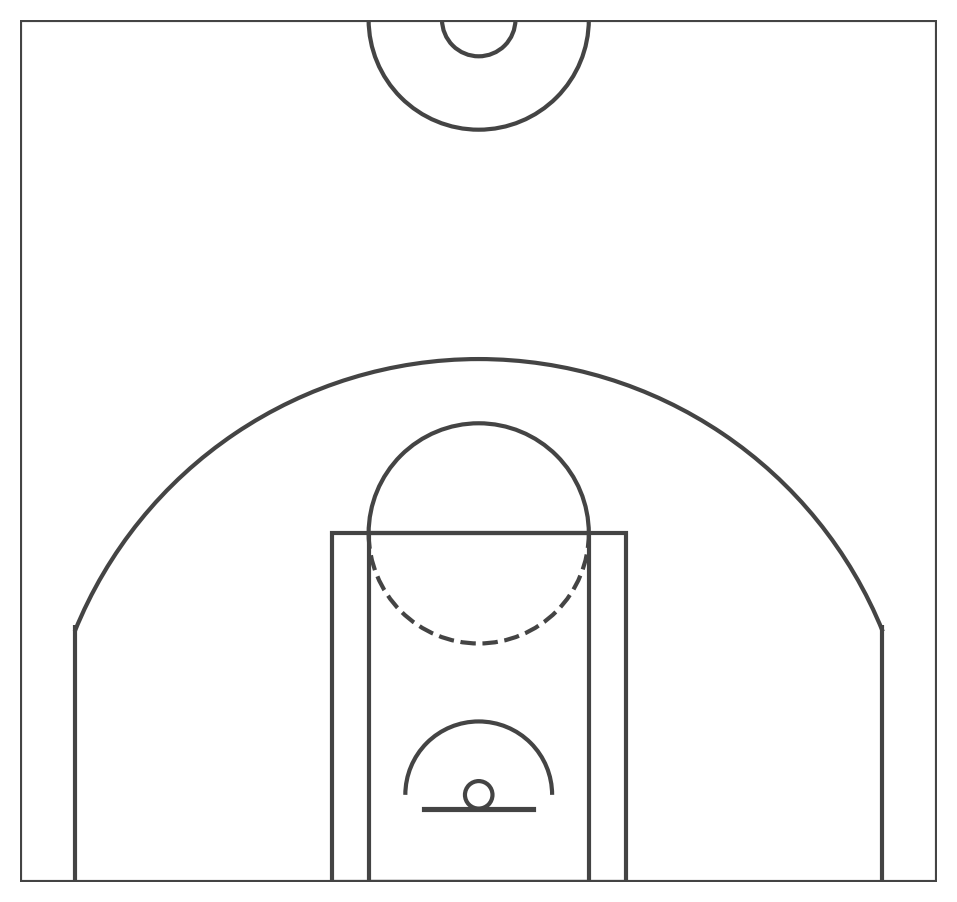

In [7]:
def draw_half_court(ax=None, color="#444", lw=1.5):
    ax = ax or plt.gca()
    elements = [
        Circle((0, 0), radius=7.5, lw=lw, color=color, fill=False),              # hoop (18 in)
        Rectangle((-30, -7.5), 60, -1, lw=lw, color=color),                      # backboard (6 ft)
        Rectangle((-80, -47.5), 160, 190, lw=lw, color=color, fill=False),       # paint (16 ft wide)
        Rectangle((-60, -47.5), 120, 190, lw=lw, color=color, fill=False),       # inner lane
        Arc((0, 142.5), 120, 120, theta1=0, theta2=180, lw=lw, color=color),     # free-throw circle
        Arc((0, 142.5), 120, 120, theta1=180, theta2=0, lw=lw, color=color, linestyle="dashed"),
        Arc((0, 0), 80, 80, theta1=0, theta2=180, lw=lw, color=color),           # restricted area (4 ft)
        Rectangle((-220, -47.5), 0, 140, lw=lw, color=color),                    # corner threes (22 ft)
        Rectangle((220, -47.5), 0, 140, lw=lw, color=color),
        Arc((0, 0), 475, 475, theta1=22, theta2=158, lw=lw, color=color),        # 3PT arc (23.75 ft)
        Arc((0, 422.5), 120, 120, theta1=180, theta2=0, lw=lw, color=color),     # center circle
        Arc((0, 422.5), 40, 40, theta1=180, theta2=0, lw=lw, color=color),
        Rectangle((-250, -47.5), 500, 470, lw=lw, color=color, fill=False),      # boundary
    ]
    for e in elements:
        ax.add_patch(e)
    ax.set_xlim(-250, 250)
    ax.set_ylim(-47.5, 422.5)
    ax.set_aspect("equal")
    ax.axis("off")
    return ax


fig, ax = plt.subplots(figsize=(6, 5.6))
draw_half_court(ax)
plt.show()

## 4. Plot made and missed shots

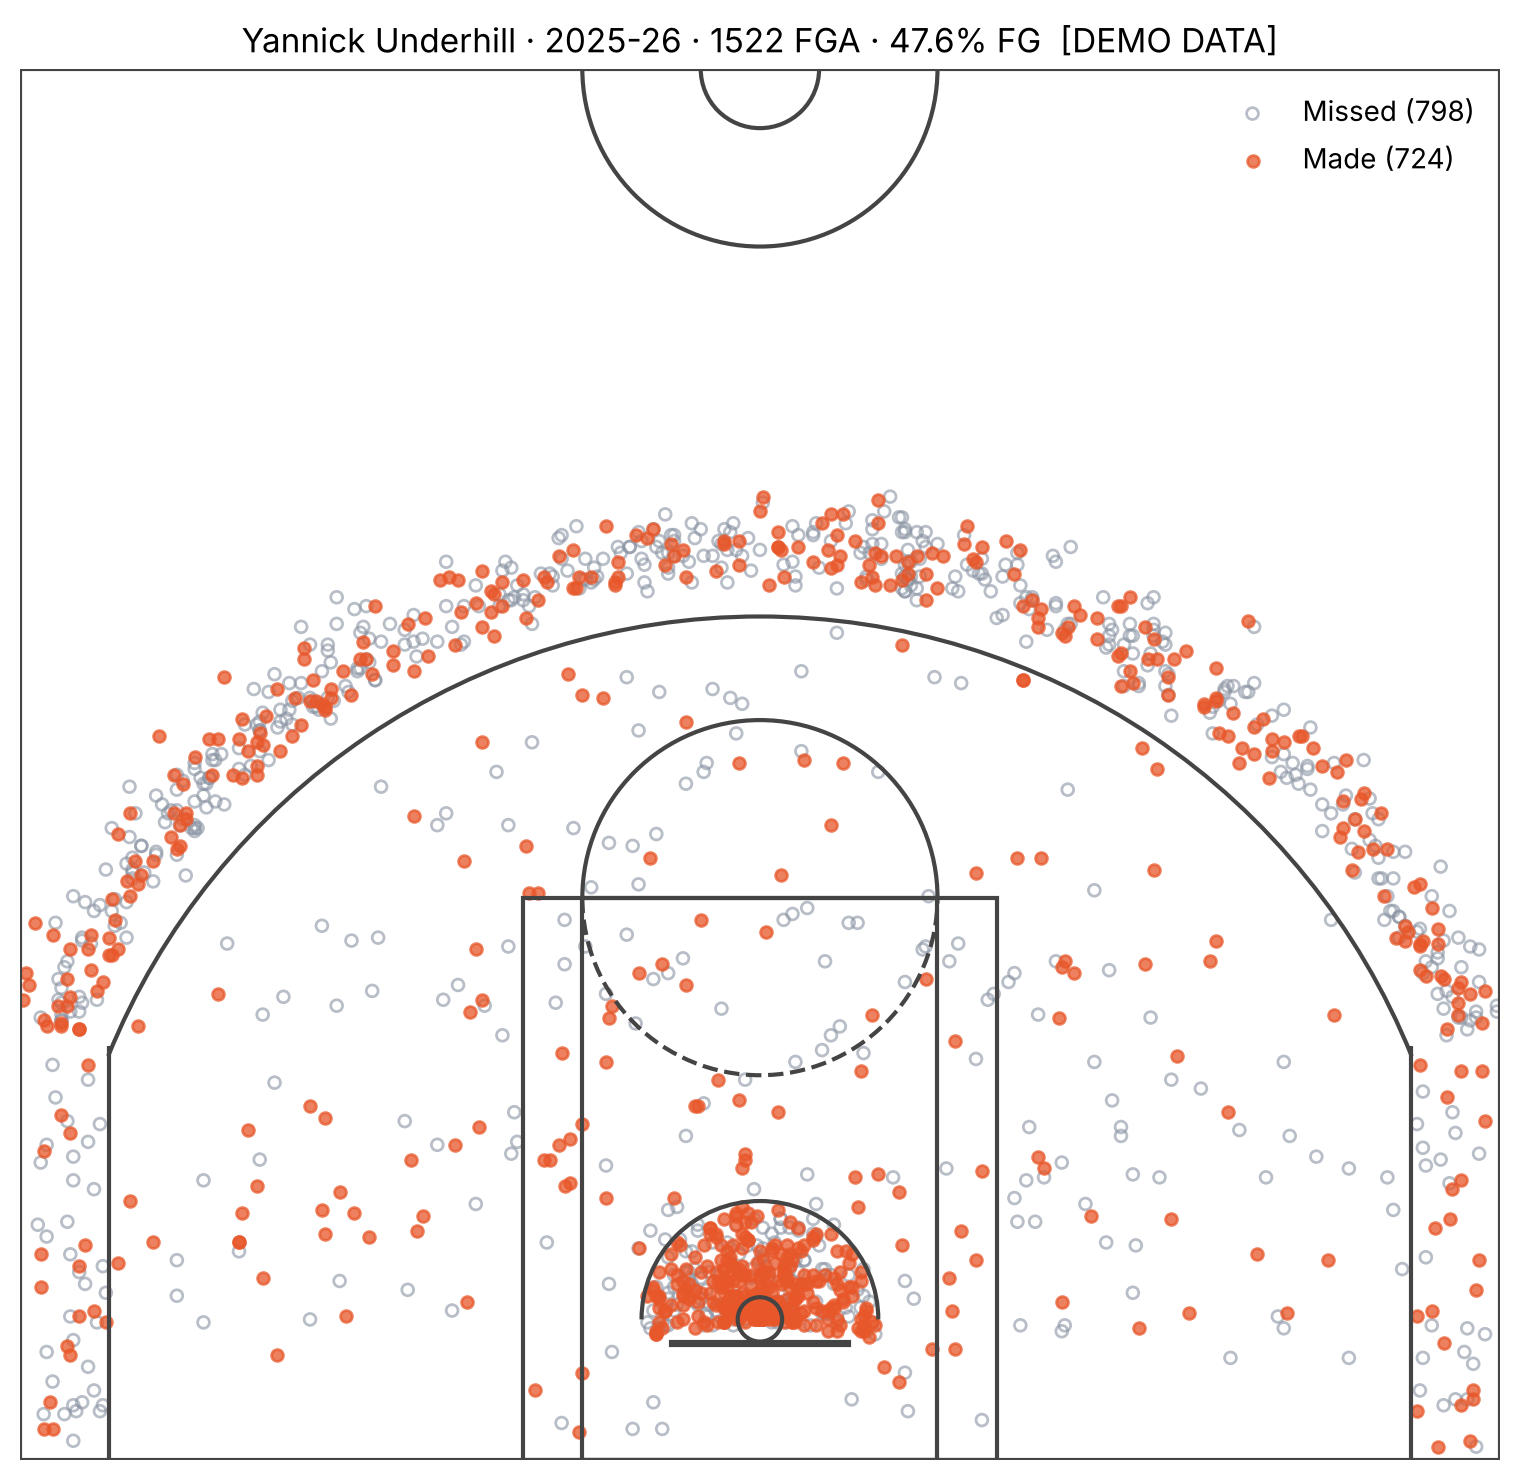

In [8]:
made = shots[shots["SHOT_MADE_FLAG"] == 1]
missed = shots[shots["SHOT_MADE_FLAG"] == 0]
fg = shots["SHOT_MADE_FLAG"].mean()

fig, ax = plt.subplots(figsize=(8, 7.5))
ax.scatter(missed["LOC_X"], missed["LOC_Y"], s=18, facecolors="none", edgecolors="#8a94a3", alpha=0.6, label=f"Missed ({len(missed)})")
ax.scatter(made["LOC_X"], made["LOC_Y"], s=18, color="#e8572a", alpha=0.75, label=f"Made ({len(made)})")
draw_half_court(ax)
ax.set_title(f"{TITLE_NAME} · {SEASON} · {len(shots)} FGA · {fg:.1%} FG  [{SOURCE}]", fontsize=12)
ax.legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.show()

## 5. Bonus: where is he efficient?
`hexbin` with `C=` averages the make flag inside each hexagon, giving FG% by location.
`mincnt` hides hexes with too few attempts to mean anything.

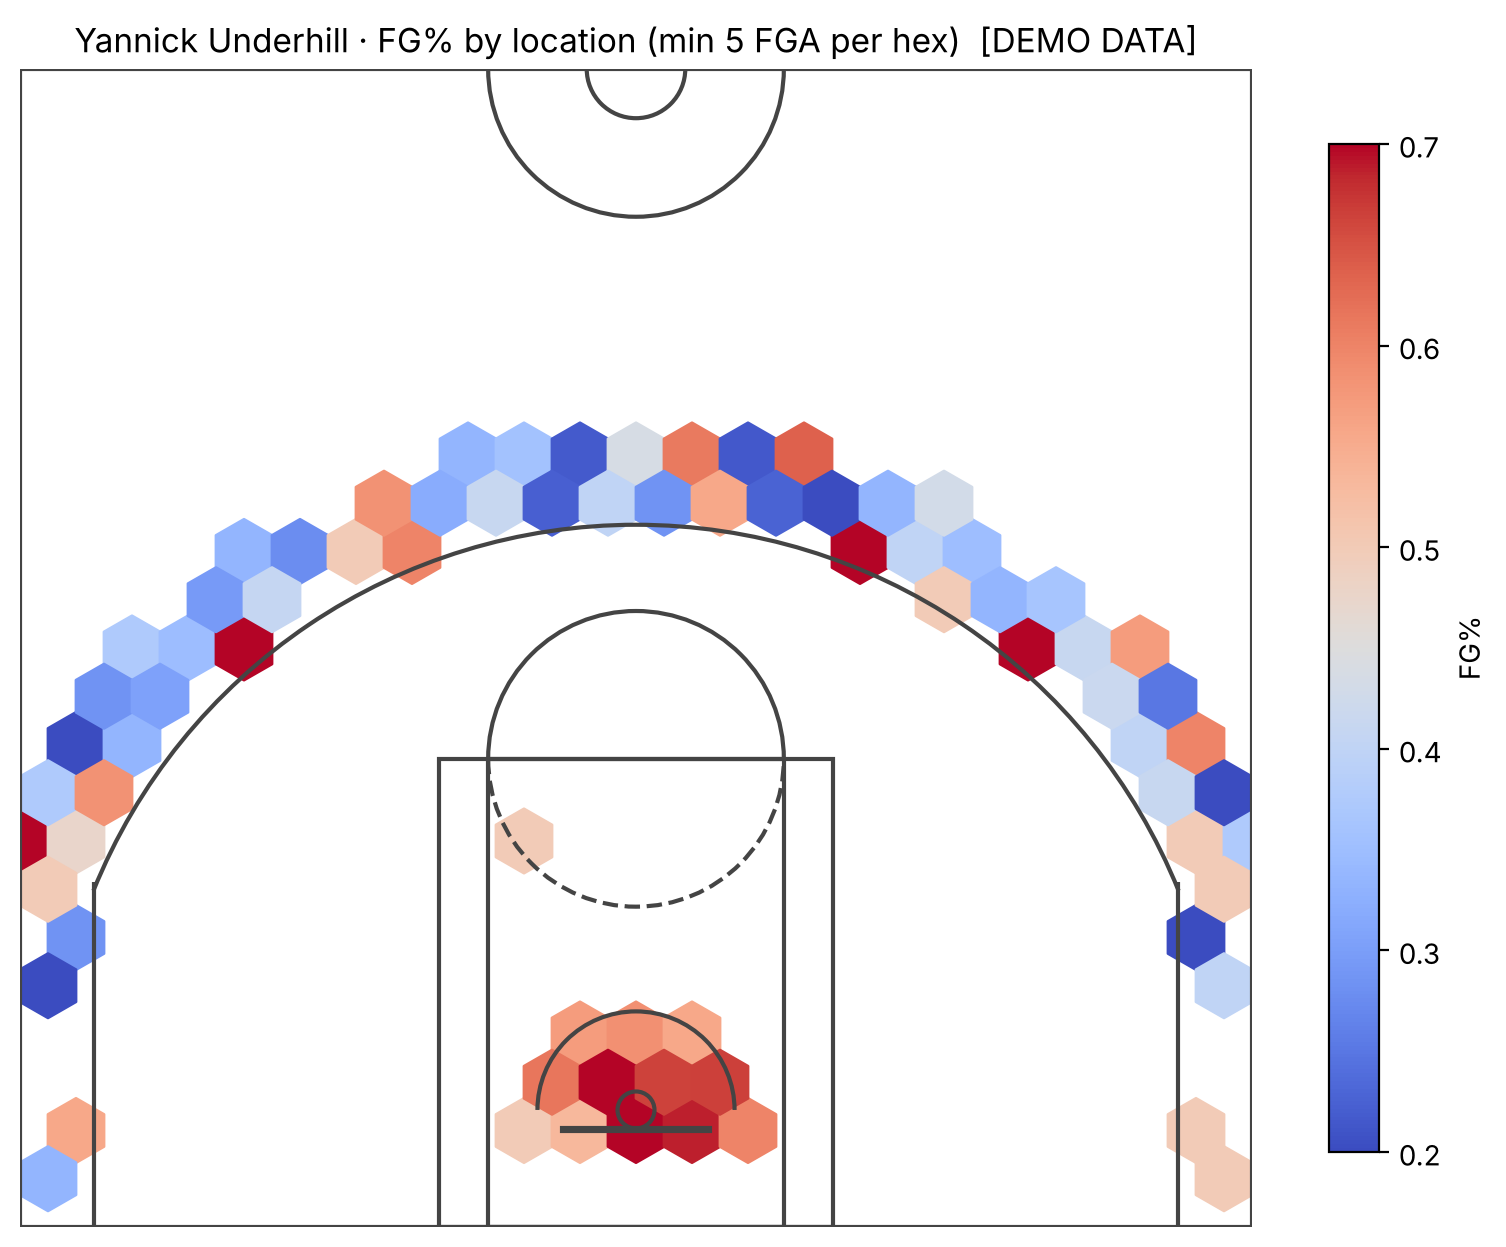

In [9]:
fig, ax = plt.subplots(figsize=(8, 7.5))
hb = ax.hexbin(shots["LOC_X"], shots["LOC_Y"], C=shots["SHOT_MADE_FLAG"], reduce_C_function=np.mean,
               gridsize=22, extent=(-250, 250, -47.5, 422.5), mincnt=5, cmap="coolwarm", vmin=0.2, vmax=0.7)
draw_half_court(ax)
fig.colorbar(hb, ax=ax, shrink=0.7, label="FG%")
ax.set_title(f"{TITLE_NAME} · FG% by location (min 5 FGA per hex)  [{SOURCE}]", fontsize=12)
plt.tight_layout()
plt.show()

## Next
- The site's hot-zone view compares each hex to the **league** FG% from that spot, not a fixed color scale. See `hoopscholar/metrics.py → hexbin`.
- `scripts/backfill.py` pulls these same shots for every player (one request per team) into SQLite.